# The Impact of Rising Tuition on Student Loan Debt📝

![Banner](./assets/banner.jpeg)

## Topic
*What problem are you (or your stakeholder) trying to address?*

📝 <!-- Answer Below -->
Higher education costs in the United States have risen steadily for decades, outpacing wage growth and household income. As tuition increases, students rely more heavily on loans, leading to long-term financial strain, delayed homeownership, reduced savings, and widening socioeconomic gaps. This project aims to address the core problem: Is the growth in student loan debt primarily driven by rising tuition, stagnant income, or both? How has affordability changed over time?


## Project Question
*What specific question are you seeking to answer with this project?*
<!--*This is not the same as the questions you ask to limit the scope of the project.*
📝 <!-- Answer Below -->
How have rising tuition costs impacted student loan debt over the years, based on average student/household income?

## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->

TUITION VS INCOME OVER TIME (LINE CHART)

Income ↑
$90k |                               _____________
$80k |                        ______/
$70k |                 ______/
$60k |          ______/
$50k |   ______/
$40k |__/
       2000   2005   2010   2015   2020   2025

Tuition ↑
$14k |                               __________________
$12k |                        ______/
$10k |                 ______/
 $8k |          ______/
 $6k |   ______/
 $4k |__/

INTERPRETATION: Tuition rises faster than income, leading to a decline in affordability.

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*
📝 <!-- Answer Below -->

.- College Tuition Dataset from College Board Trends in College Pricing (Table CP-3)

.- Median Household Income from U.S. Census ACS

.- Merged Final Dataset (merged on Year)

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

In [70]:
#import
import os
import pandas as pd
from dotenv import load_dotenv
from fredapi import Fred
import requests
import matplotlib.pyplot as plt

load_dotenv(dotenv_path=r"C:\Users\braea\OneDrive\Documents\GitHub\data-tech-analytics-final-project-braeaussie\.env")
load_dotenv(override=True)

True

In [41]:
fred_api_key = os.getenv("FRED_API_KEY")
census_api_key = os.getenv("CENSUS_API_KEY")

In [75]:
# Load Data

# Tuition
tuition = pd.read_excel(
    "data/TrendsinCollegePricing2025.xlsx",
    sheet_name="Table CP-3",
    skiprows=2
)

# Student loan debt
fred = Fred(api_key=fred_api_key)

loan_debt = fred.get_series("SLOAS").to_frame(
    name="Student_Loan_Debt"
)

loan_debt.index = loan_debt.index.year

loan_debt = (
    loan_debt.groupby(loan_debt.index)
    .mean()
    .reset_index()
    .rename(columns={"index": "Year"})
)

# Income
income = fred.get_series("MEHOINUSA646N").to_frame(
    name="Median_Income")

income.index = income.index.year

income = (
    income.groupby(income.index)
    .mean()
    .reset_index()
    .rename(columns={"index": "Year"})
)


In [77]:
# Rename Tuition Academic Year --> Year
tuition = tuition.rename(columns={"Academic Year": "Year"})

In [78]:
# Convert Academic Years
tuition = tuition[
    tuition["Year"].astype(str).str.match(r"^\d{2}-\d{2}$", na=False)
]

tuition["Year"] = (
    tuition["Year"]
    .str[:2]
    .astype(int)
    .apply(lambda x: x + 1900 if x >= 86 else x + 2000)
)


In [79]:
df = tuition.merge(loan_debt, on="Year").merge(
    income[["Year", "Median_Income"]],
    on="Year",
    how="left"
)

In [80]:
# Save final dataset
df.to_csv("data/final_dataset.csv", index=False)

print(df.head())
print(df.info())

   Year  Public Two-Year  Public Four-Year  Private Nonprofit Four-Year  \
0  2006           2460.0            5450.0                      19360.0   
1  2007           2460.0            5880.0                      19850.0   
2  2008           2550.0            6270.0                      21160.0   
3  2009           2720.0            6700.0                      22170.0   
4  2010           2890.0            7170.0                      23170.0   

   Unnamed: 4  Public Two-Year.1  Public Four-Year.1  \
0         NaN             3930.0              8700.0   
1         NaN             3820.0              9130.0   
2         NaN             3810.0              9380.0   
3         NaN             4080.0             10060.0   
4         NaN             4270.0             10590.0   

   Private Nonprofit Four-Year.1  Unnamed: 8  Student_Loan_Debt  Median_Income  
0                        30920.0         NaN        500005.9925        48200.0  
1                        30830.0         NaN      

In [81]:
# Remove Unnamed/Unnecessary Columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [83]:
# Rename Columns
df = df.rename(columns={
    "Public Two-Year": "Public Two-Year at the Time",
    "Public Four-Year": "Public Four-Year at the Time",
    "Private Nonprofit Four-Year": "Private Nonprofit Four-Year at the Time",
    "Public Two-Year.1": "Public Two-Year in 2025 Dollars",
    "Public Four-Year.1": "Public Four-Year in 2025 Dollars",
    "Private Nonprofit Four-Year.1": "Private Nonprofit Four-Year in 2025 Dollars"
})

In [84]:
# Initial Data Inspection

# How many records are available?
# What are the variable types?
# Are there missing values?
# What are the summary statistics?

df.info()

df.describe()

df.head()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 9 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Year                                         19 non-null     int64  
 1   Public Two-Year at the Time                  19 non-null     float64
 2   Public Four-Year at the Time                 19 non-null     float64
 3   Private Nonprofit Four-Year at the Time      19 non-null     float64
 4   Public Two-Year in 2025 Dollars              19 non-null     float64
 5   Public Four-Year in 2025 Dollars             19 non-null     float64
 6   Private Nonprofit Four-Year in 2025 Dollars  19 non-null     float64
 7   Student_Loan_Debt                            19 non-null     float64
 8   Median_Income                                19 non-null     float64
dtypes: float64(8), int64(1)
memory usage: 1.5 KB


,Year,Public Two-Year at the Time,Public Four-Year at the Time,Private Nonprofit Four-Year at the Time,Public Two-Year in 2025 Dollars,Public Four-Year in 2025 Dollars,Private Nonprofit Four-Year in 2025 Dollars,Student_Loan_Debt,Median_Income
0,2006,2460.0,5450.0,19360.0,3930.0,8700.0,30920.0,500005.9925,48200.0
1,2007,2460.0,5880.0,19850.0,3820.0,9130.0,30830.0,565282.3050,50230.0
2,2008,2550.0,6270.0,21160.0,3810.0,9380.0,31640.0,645614.5700,50300.0
3,2009,2720.0,6700.0,22170.0,4080.0,10060.0,33270.0,734442.0600,49780.0
4,2010,2890.0,7170.0,23170.0,4270.0,10590.0,34210.0,828126.7000,49280.0


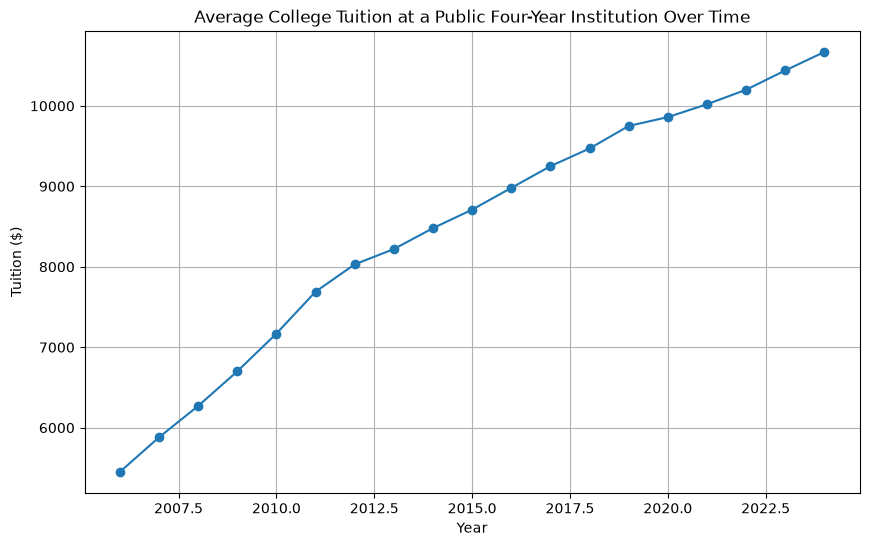

In [ ]:
# Tuition Over Time Line Graph
# Shows the historical growth of tuition at public four-year institutions in the United States.
plt.figure(figsize=(10,6))
plt.plot(df["Year"], df["Public Four-Year at the Time"], marker="o")
plt.title("Average College Tuition at a Public Four-Year Institution Over Time")
plt.xlabel("Year")
plt.ylabel("Tuition ($)")
plt.grid(True)
plt.show()

# Tuition is expected to increase steadily over time, indicating rising educational costs.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

In [ ]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 1271 bytes to source.py
